In [1]:
import pandas as pd
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

PROJECT_DIR = Path.cwd().parent

prediction_path = (
    PROJECT_DIR / "reports" /
    "ludhiana_2025_test_predictions.csv"
)

df = pd.read_csv(prediction_path, parse_dates=["date"])

print("Number of test days:", len(df))
print("\nFirst 15 predictions:")
display(df.head(15).round(2))

print("\nRainfall statistics:")
display(
    df[["actual_rainfall_mm", "predicted_rainfall_mm"]]
    .describe()
    .round(2)
)

print("\nDays with the largest prediction errors:")
df["absolute_error_mm"] = (
    df["actual_rainfall_mm"] -
    df["predicted_rainfall_mm"]
).abs()

display(
    df.sort_values("absolute_error_mm", ascending=False)
    .head(10)
    .round(2)
)

Number of test days: 73

First 15 predictions:


C:\Users\balve\AppData\Local\Temp\ipykernel_148444\3241058122.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df.head(15).round(2))


,date,actual_rainfall_mm,predicted_rainfall_mm
0,2025-10-20,0.0,0.19
1,2025-10-21,0.3,0.16
2,2025-10-22,0.0,0.07
3,2025-10-23,0.0,0.03
4,2025-10-24,0.0,0.22
5,2025-10-25,0.0,0.22
6,2025-10-26,0.0,0.21
7,2025-10-27,0.0,0.22
8,2025-10-28,0.0,0.26
9,2025-10-29,0.0,0.26



Rainfall statistics:


,actual_rainfall_mm,predicted_rainfall_mm
count,73.00,73.00
mean,0.00,2.73
std,0.04,6.06
min,0.00,0.00
25%,0.00,0.05
50%,0.00,0.22
75%,0.00,1.62
max,0.30,24.27



Days with the largest prediction errors:


C:\Users\balve\AppData\Local\Temp\ipykernel_148444\3241058122.py:35: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,date,actual_rainfall_mm,predicted_rainfall_mm,absolute_error_mm
60,2025-12-19,0.0,24.27,24.27
61,2025-12-20,0.0,21.16,21.16
72,2025-12-31,0.0,20.83,20.83
59,2025-12-18,0.0,20.78,20.78
62,2025-12-21,0.0,20.78,20.78
54,2025-12-13,0.0,20.20,20.20
55,2025-12-14,0.0,16.20,16.20
70,2025-12-29,0.0,8.09,8.09
58,2025-12-17,0.0,4.68,4.68
57,2025-12-16,0.0,4.01,4.01


In [2]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

data_path = (
    PROJECT_DIR / "data" / "processed" /
    "ludhiana_2025_ml_training_data.csv"
)

df = pd.read_csv(data_path, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

# Inspect the final three months
late_year = df[
    df["date"] >= "2025-10-01"
].copy()

print("Dates covered:", late_year["date"].min().date(),
      "to", late_year["date"].max().date())

print("\nMonthly rainfall summary:")
late_year["month"] = late_year["date"].dt.to_period("M")

display(
    late_year.groupby("month")["observed_rainfall_mm"]
    .agg(["count", "sum", "mean", "max"])
    .round(3)
)

print("\nDaily rainfall from December 10 to December 31:")
display(
    late_year.loc[
        late_year["date"] >= "2025-12-10",
        ["date", "observed_rainfall_mm",
         "temperature_mean_c", "humidity_mean_pct",
         "dew_point_mean_c", "cloud_cover_mean_pct",
         "wind_speed_mean_kmh"]
    ].round(2).to_string(index=False)
)

Dates covered: 2025-10-01 to 2025-12-31

Monthly rainfall summary:


,count,sum,mean,max
month,,,,
2025-10,31,40.0,1.29,13.2
2025-11,30,0.0,0.00,0.0
2025-12,31,0.0,0.00,0.0



Daily rainfall from December 10 to December 31:


C:\Users\balve\AppData\Local\Temp\ipykernel_148444\1950427828.py:39: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2).to_string(index=False)


'      date  observed_rainfall_mm  temperature_mean_c  humidity_mean_pct  dew_point_mean_c  cloud_cover_mean_pct  wind_speed_mean_kmh\n2025-12-10                   0.0               13.37              75.38              8.42                 37.21                 5.40\n2025-12-11                   0.0               13.59              76.83              8.82                  6.46                 4.65\n2025-12-12                   0.0               14.32              77.79              9.90                 73.00                 3.26\n2025-12-13                   0.0               14.34              77.54             10.08                 87.33                 5.01\n2025-12-14                   0.0               14.68              77.92             10.46                 84.83                 3.77\n2025-12-15                   0.0               14.45              77.17              9.95                 37.96                 7.92\n2025-12-16                   0.0               13.80         

In [3]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

data = pd.read_csv(
    PROJECT_DIR / "data" / "processed" /
    "ludhiana_2025_ml_training_data.csv",
    parse_dates=["date"]
)

pred = pd.read_csv(
    PROJECT_DIR / "reports" /
    "ludhiana_2025_test_predictions.csv",
    parse_dates=["date"]
)

check = data.merge(pred, on="date", how="inner")

print("December 2025: actual versus predicted rainfall")

display(
    check.loc[
        check["date"].dt.month == 12,
        [
            "date",
            "observed_rainfall_mm",
            "predicted_rainfall_mm",
            "temperature_mean_c",
            "humidity_mean_pct",
            "dew_point_mean_c",
            "cloud_cover_mean_pct",
            "wind_speed_mean_kmh"
        ]
    ].round(2).to_string(index=False)
)

December 2025: actual versus predicted rainfall


C:\Users\balve\AppData\Local\Temp\ipykernel_148444\2246331582.py:35: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2).to_string(index=False)


'      date  observed_rainfall_mm  predicted_rainfall_mm  temperature_mean_c  humidity_mean_pct  dew_point_mean_c  cloud_cover_mean_pct  wind_speed_mean_kmh\n2025-12-01                   0.0                   0.88               12.68              64.00              5.08                 31.96                 2.34\n2025-12-02                   0.0                   0.01               12.33              65.83              5.39                  0.04                 3.97\n2025-12-03                   0.0                   0.01               12.07              70.92              6.24                  0.00                 6.17\n2025-12-04                   0.0                   1.29               11.84              73.54              6.62                 28.38                 6.40\n2025-12-05                   0.0                   1.04               12.20              70.21              6.20                 14.83                 5.09\n2025-12-06                   0.0                   3.33  

In [4]:
december = check.loc[
    check["date"].dt.month == 12,
    [
        "date",
        "observed_rainfall_mm",
        "predicted_rainfall_mm",
        "temperature_mean_c",
        "humidity_mean_pct",
        "dew_point_mean_c",
        "cloud_cover_mean_pct",
        "wind_speed_mean_kmh"
    ]
].copy()

december["date"] = december["date"].dt.strftime("%Y-%m-%d")

print("December rows:", len(december))
print(december.round(2).to_string(index=False))

December rows: 31
      date  observed_rainfall_mm  predicted_rainfall_mm  temperature_mean_c  humidity_mean_pct  dew_point_mean_c  cloud_cover_mean_pct  wind_speed_mean_kmh
2025-12-01                   0.0                   0.88               12.68              64.00              5.08                 31.96                 2.34
2025-12-02                   0.0                   0.01               12.33              65.83              5.39                  0.04                 3.97
2025-12-03                   0.0                   0.01               12.07              70.92              6.24                  0.00                 6.17
2025-12-04                   0.0                   1.29               11.84              73.54              6.62                 28.38                 6.40
2025-12-05                   0.0                   1.04               12.20              70.21              6.20                 14.83                 5.09
2025-12-06                   0.0              

In [5]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

# Load the original forecast-versus-rainfall comparison
comparison_path = (
    PROJECT_DIR / "data" / "processed" /
    "ludhiana_2025_forecast_rainfall_comparison.csv"
)

comparison = pd.read_csv(comparison_path, parse_dates=["date"])

# Load RainfallAI model predictions
predictions_path = (
    PROJECT_DIR / "reports" /
    "ludhiana_2025_test_predictions.csv"
)

predictions = pd.read_csv(predictions_path, parse_dates=["date"])

print("Comparison dataset:", comparison.shape)
print("Prediction dataset:", predictions.shape)

print("\nPrediction columns:")
print(predictions.columns.tolist())

print("\nFirst five model predictions:")
display(predictions.head())

Comparison dataset: (365, 10)
Prediction dataset: (73, 3)

Prediction columns:
['date', 'actual_rainfall_mm', 'predicted_rainfall_mm']

First five model predictions:


,date,actual_rainfall_mm,predicted_rainfall_mm
0,2025-10-20,0.0,0.188362
1,2025-10-21,0.3,0.161228
2,2025-10-22,0.0,0.066469
3,2025-10-23,0.0,0.033049
4,2025-10-24,0.0,0.221807


In [6]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Match the original weather forecast to the model's test dates
comparison["date"] = pd.to_datetime(comparison["date"])
predictions["date"] = pd.to_datetime(predictions["date"])

test = predictions.merge(
    comparison[
        ["date", "precipitation_sum_mm",
         "observed_precipitation_mm", "observed_rainfall_mm"]
    ],
    on="date",
    how="left",
    validate="one_to_one"
)

assert len(test) == len(predictions), "Some prediction dates did not match!"
assert test["precipitation_sum_mm"].notna().all(), "Missing forecast values!"
assert test["observed_rainfall_mm"].notna().all(), "Missing rainfall values!"

# Use the same rainfall target for a fair comparison.
# The original forecast provides total precipitation, while the model
# predicts rainfall, so this comparison is approximate.
y_actual = test["actual_rainfall_mm"]

results = []

# RainfallAI model
results.append({
    "Method": "RainfallAI model",
    "MAE (mm)": mean_absolute_error(
        y_actual, test["predicted_rainfall_mm"]
    ),
    "RMSE (mm)": np.sqrt(mean_squared_error(
        y_actual, test["predicted_rainfall_mm"]
    ))
})

# Original forecast precipitation
results.append({
    "Method": "Original weather forecast",
    "MAE (mm)": mean_absolute_error(
        y_actual, test["precipitation_sum_mm"]
    ),
    "RMSE (mm)": np.sqrt(mean_squared_error(
        y_actual, test["precipitation_sum_mm"]
    ))
})

# Simple baseline: predict the average rainfall from the model's training period
training_mean = predictions["actual_rainfall_mm"].mean()

results.append({
    "Method": "Training-period mean baseline",
    "MAE (mm)": mean_absolute_error(
        y_actual, np.full(len(test), training_mean)
    ),
    "RMSE (mm)": np.sqrt(mean_squared_error(
        y_actual, np.full(len(test), training_mean)
    ))
})

results_df = pd.DataFrame(results).round(3)

print("TEST PERIOD:", test["date"].min().date(), "to", test["date"].max().date())
print("TEST DAYS:", len(test))
display(results_df)

TEST PERIOD: 2025-10-20 to 2025-12-31
TEST DAYS: 73


,Method,MAE (mm),RMSE (mm)
0,RainfallAI model,2.731,6.606
1,Original weather forecast,0.033,0.157
2,Training-period mean baseline,0.008,0.035


In [7]:

# Check how much rainfall actually occurred during the test period

print("Number of test days:", len(test))

print(
    "Days with zero rainfall:",
    (test["actual_rainfall_mm"] == 0).sum()
)

print(
    "Days with rainfall:",
    (test["actual_rainfall_mm"] > 0).sum()
)

print(
    "Average actual rainfall:",
    round(test["actual_rainfall_mm"].mean(), 3), "mm"
)

print(
    "Maximum actual rainfall:",
    round(test["actual_rainfall_mm"].max(), 3), "mm"
)

print("\nRainfallAI prediction summary:")
display(test["predicted_rainfall_mm"].describe())

print("\nOriginal forecast precipitation summary:")
display(test["precipitation_sum_mm"].describe())


Number of test days: 73
Days with zero rainfall: 72
Days with rainfall: 1
Average actual rainfall: 0.004 mm
Maximum actual rainfall: 0.3 mm

RainfallAI prediction summary:


count    73.000000
mean      2.730902
std       6.056563
min       0.003610
25%       0.046310
50%       0.221807
75%       1.624176
max      24.270351
Name: predicted_rainfall_mm, dtype: float64


Original forecast precipitation summary:


count    73.000000
mean      0.028767
std       0.151364
min       0.000000
25%       0.000000
50%       0.000000
75%       0.000000
max       0.900000
Name: precipitation_sum_mm, dtype: float64

In [8]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

data_path = (
    PROJECT_DIR / "data" / "processed" /
    "ludhiana_2025_ml_training_data.csv"
)

full_data = pd.read_csv(data_path, parse_dates=["date"])

# Add month names
full_data["month"] = full_data["date"].dt.month_name()

# Summarize rainfall by month
monthly_summary = (
    full_data.groupby(full_data["date"].dt.month)
    .agg(
        days=("observed_rainfall_mm", "size"),
        rainy_days=("observed_rainfall_mm", lambda x: (x > 0).sum()),
        total_rainfall_mm=("observed_rainfall_mm", "sum"),
        average_rainfall_mm=("observed_rainfall_mm", "mean"),
        maximum_rainfall_mm=("observed_rainfall_mm", "max")
    )
    .round(2)
)

monthly_summary.index = [
    pd.Timestamp(month=m, year=2025, day=1).strftime("%B")
    for m in monthly_summary.index
]

display(monthly_summary)

print("\nOverall rainy days:",
      (full_data["observed_rainfall_mm"] > 0).sum())

print("Overall dry days:",
      (full_data["observed_rainfall_mm"] == 0).sum())

print("Overall maximum rainfall:",
      full_data["observed_rainfall_mm"].max(), "mm")


,days,rainy_days,total_rainfall_mm,average_rainfall_mm,maximum_rainfall_mm
January,31,5,24.1,0.78,9.0
February,28,10,74.0,2.64,45.8
March,31,8,15.8,0.51,7.9
April,30,5,5.6,0.19,2.3
May,31,12,29.7,0.96,10.8
June,30,15,94.2,3.14,27.8
July,31,26,167.4,5.40,32.0
August,31,29,315.2,10.17,54.6
September,30,19,138.5,4.62,75.6
October,31,9,40.0,1.29,13.2



Overall rainy days: 138
Overall dry days: 227
Overall maximum rainfall: 75.6 mm


In [9]:

# STEP 76 — Load data and saved model

from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

# Find the project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "raw" / "ludhiana_rainfall_reference_2022_2025.csv"
model_dir = project_root / "model"

if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found: {data_path}")

config_path = model_dir / "feature_config.joblib"
if not config_path.exists():
    raise FileNotFoundError(f"Model configuration not found: {config_path}")

config = joblib.load(config_path)

data_df = pd.read_csv(data_path)
data_df["date"] = pd.to_datetime(data_df["date"])
data_df = data_df.sort_values("date").reset_index(drop=True)

data_df["tomorrow_rainfall_mm"] = (
    data_df["observed_rainfall_mm"].shift(-1)
)

data_df = data_df.dropna(
    subset=["tomorrow_rainfall_mm"]
).reset_index(drop=True)

print("EVALUATION DATA LOADED")
print("-" * 35)
print("Project folder:", project_root)
print("Rows:", len(data_df))
print("Date range:", data_df["date"].min().date(),
      "to", data_df["date"].max().date())
print("Saved model:", config["best_model_name"])
print("Encoded features:", config["encoded_feature_columns"])


EVALUATION DATA LOADED
-----------------------------------
Project folder: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026
Rows: 1460
Date range: 2022-01-01 to 2025-12-30
Saved model: Gradient Boosting
Encoded features: ['observed_rainfall_mm', 'month', 'day_of_year', 'day_of_week', 'season_Monsoon', 'season_Post-Monsoon', 'season_Summer', 'season_Winter']


In [10]:

# STEP 77 — Recreate features exactly as in training

feature_columns = config["feature_columns"]
encoded_feature_columns = config["encoded_feature_columns"]

data_df["month"] = data_df["date"].dt.month
data_df["day_of_year"] = data_df["date"].dt.dayofyear
data_df["day_of_week"] = data_df["date"].dt.dayofweek

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

data_df["season"] = data_df["month"].apply(get_season)

X_all = data_df[feature_columns].copy()
X_all = pd.get_dummies(
    X_all,
    columns=["season"],
    dtype=int
)

# Ensure identical feature columns and order
X_all = X_all.reindex(
    columns=encoded_feature_columns,
    fill_value=0
)

y_all = data_df["tomorrow_rainfall_mm"].copy()

print("FEATURE PREPARATION COMPLETE")
print("-" * 35)
print("Feature matrix shape:", X_all.shape)
print("Target shape:", y_all.shape)
print("Features match training configuration:",
      X_all.columns.tolist() == encoded_feature_columns)
print("\nFirst 5 prepared rows:")
print(X_all.head().to_string(index=False))


FEATURE PREPARATION COMPLETE
-----------------------------------
Feature matrix shape: (1460, 8)
Target shape: (1460,)
Features match training configuration: True

First 5 prepared rows:
 observed_rainfall_mm  month  day_of_year  day_of_week  season_Monsoon  season_Post-Monsoon  season_Summer  season_Winter
                  0.0      1            1            5               0                    0              0              1
                  0.0      1            2            6               0                    0              0              1
                  0.0      1            3            0               0                    0              0              1
                  1.0      1            4            1               0                    0              0              1
                 24.3      1            5            2               0                    0              0              1


In [11]:

# STEP 78 — Recreate chronological split

split_index = int(len(data_df) * 0.80)

X_train_eval = X_all.iloc[:split_index].copy()
X_test = X_all.iloc[split_index:].copy()

y_train_eval = y_all.iloc[:split_index].copy()
y_test = y_all.iloc[split_index:].copy()

test_dates = data_df["date"].iloc[split_index:].reset_index(drop=True)

print("Training rows:", len(X_train_eval))
print("Test rows:", len(X_test))
print("Test date range:",
      test_dates.min().date(), "to", test_dates.max().date())


Training rows: 1168
Test rows: 292
Test date range: 2025-03-14 to 2025-12-30


In [12]:

# STEP 79 — Load saved model

best_model_name = config["best_model_name"]

model_files = {
    "Random Forest": "rainfall_model.joblib",
    "Extra Trees": "rainfall_model.joblib",
    "Gradient Boosting": "rainfall_model.joblib"
}

model_path = model_dir / model_files[best_model_name]

if not model_path.exists():
    raise FileNotFoundError(
        f"Saved model not found: {model_path}. "
        "Check Step 74 in the training notebook."
    )

best_model = joblib.load(model_path)

print("Loaded model:", best_model_name)
print("Model file:", model_path)


Loaded model: Gradient Boosting
Model file: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\model\rainfall_model.joblib


In [13]:

# STEP 80 — Generate predictions

from sklearn.ensemble import GradientBoostingRegressor

print("Loaded model type:", type(best_model).__name__)

if not isinstance(best_model, GradientBoostingRegressor):
    raise TypeError(
        "The loaded model is not GradientBoostingRegressor, "
        "but the configuration says Gradient Boosting. "
        "Verify the saved model and configuration."
    )

raw_predictions = best_model.predict(X_test)

# Rainfall cannot be negative
predictions = np.maximum(raw_predictions, 0)

evaluation_df = pd.DataFrame({
    "date": test_dates,
    "actual_rainfall_mm": y_test.reset_index(drop=True),
    "predicted_rainfall_mm": predictions
})

evaluation_df["absolute_error_mm"] = np.abs(
    evaluation_df["actual_rainfall_mm"] -
    evaluation_df["predicted_rainfall_mm"]
)

print(evaluation_df.head(10).round(2).to_string(index=False))


Loaded model type: GradientBoostingRegressor
      date  actual_rainfall_mm  predicted_rainfall_mm  absolute_error_mm
2025-03-14                 7.9                   1.55               6.35
2025-03-15                 0.1                   2.22               2.12
2025-03-16                 0.0                   0.53               0.53
2025-03-17                 0.0                   0.19               0.19
2025-03-18                 0.2                   0.23               0.03
2025-03-19                 0.0                   0.70               0.70
2025-03-20                 0.0                   0.23               0.23
2025-03-21                 0.0                   0.23               0.23
2025-03-22                 0.0                   0.23               0.23
2025-03-23                 0.0                   0.23               0.23


C:\Users\balve\AppData\Local\Temp\ipykernel_148444\1843530225.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(evaluation_df.head(10).round(2).to_string(index=False))


In [14]:

# STEP 81 — Calculate evaluation metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(
    evaluation_df["actual_rainfall_mm"],
    evaluation_df["predicted_rainfall_mm"]
)

rmse = np.sqrt(mean_squared_error(
    evaluation_df["actual_rainfall_mm"],
    evaluation_df["predicted_rainfall_mm"]
))

r2 = r2_score(
    evaluation_df["actual_rainfall_mm"],
    evaluation_df["predicted_rainfall_mm"]
)

bias = (
    evaluation_df["predicted_rainfall_mm"] -
    evaluation_df["actual_rainfall_mm"]
).mean()

print("MODEL EVALUATION RESULTS")
print("-" * 40)
print(f"MAE:  {mae:.3f} mm")
print(f"RMSE: {rmse:.3f} mm")
print(f"R²:   {r2:.3f}")
print(f"Bias: {bias:.3f} mm")


MODEL EVALUATION RESULTS
----------------------------------------
MAE:  2.760 mm
RMSE: 7.851 mm
R²:   0.005
Bias: -1.596 mm


               Model  MAE_mm  RMSE_mm     R2
Persistence Baseline   3.224    9.164 -0.355
   Gradient Boosting   2.760    7.851  0.005


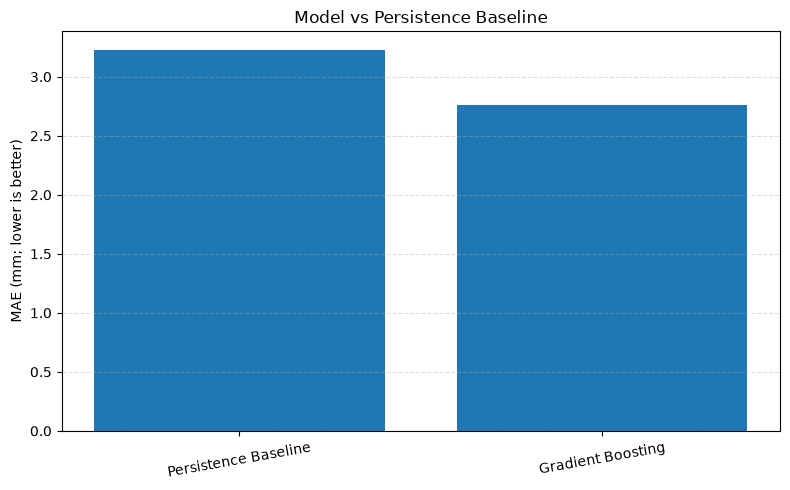

In [15]:

# STEP 82 — Compare against baseline

baseline_predictions = X_test["observed_rainfall_mm"].to_numpy()
actual = evaluation_df["actual_rainfall_mm"].to_numpy()

comparison_df = pd.DataFrame([
    {
        "Model": "Persistence Baseline",
        "MAE_mm": mean_absolute_error(actual, baseline_predictions),
        "RMSE_mm": np.sqrt(mean_squared_error(actual, baseline_predictions)),
        "R2": r2_score(actual, baseline_predictions)
    },
    {
        "Model": best_model_name,
        "MAE_mm": mean_absolute_error(
            actual, evaluation_df["predicted_rainfall_mm"]
        ),
        "RMSE_mm": np.sqrt(mean_squared_error(
            actual, evaluation_df["predicted_rainfall_mm"]
        )),
        "R2": r2_score(
            actual, evaluation_df["predicted_rainfall_mm"]
        )
    }
])

print(comparison_df.round(3).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.bar(comparison_df["Model"], comparison_df["MAE_mm"])
plt.ylabel("MAE (mm; lower is better)")
plt.title("Model vs Persistence Baseline")
plt.xticks(rotation=10)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [16]:

# STEP 83 — Inspect heavy-rainfall cases

heavy_df = evaluation_df[
    evaluation_df["actual_rainfall_mm"] >= 20
].copy()

print("HEAVY-RAINFALL EVALUATION")
print("-" * 40)
print("Test days with rainfall >= 20 mm:", len(heavy_df))

if len(heavy_df) > 0:
    print(heavy_df.round(2).to_string(index=False))
    print(
        "\nHeavy-rainfall MAE:",
        round(
            mean_absolute_error(
                heavy_df["actual_rainfall_mm"],
                heavy_df["predicted_rainfall_mm"]
            ),
            2
        ),
        "mm"
    )
else:
    print("No heavy-rainfall days occurred in this test period.")


HEAVY-RAINFALL EVALUATION
----------------------------------------
Test days with rainfall >= 20 mm: 10
      date  actual_rainfall_mm  predicted_rainfall_mm  absolute_error_mm
2025-06-27                27.8                   2.60              25.20
2025-06-28                20.6                   3.37              17.23
2025-07-21                32.0                   3.14              28.86
2025-08-11                41.0                   3.89              37.11
2025-08-23                28.1                   1.92              26.18
2025-08-24                36.7                   3.48              33.22
2025-08-26                24.3                   3.48              20.82
2025-08-30                54.6                   2.71              51.89
2025-08-31                20.1                   2.40              17.70
2025-09-02                75.6                   2.71              72.89

Heavy-rainfall MAE: 33.11 mm


C:\Users\balve\AppData\Local\Temp\ipykernel_148444\982184812.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(heavy_df.round(2).to_string(index=False))


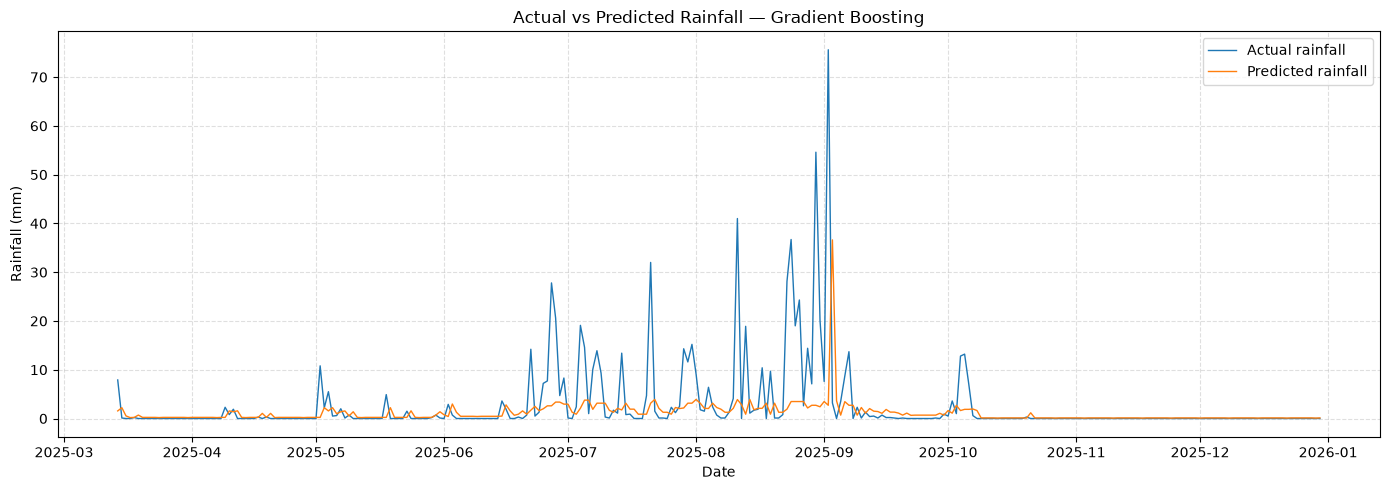

In [17]:

# STEP 84 — Plot actual and predicted rainfall

plt.figure(figsize=(14, 5))

plt.plot(
    evaluation_df["date"],
    evaluation_df["actual_rainfall_mm"],
    label="Actual rainfall",
    linewidth=1
)

plt.plot(
    evaluation_df["date"],
    evaluation_df["predicted_rainfall_mm"],
    label="Predicted rainfall",
    linewidth=1
)

plt.title(f"Actual vs Predicted Rainfall — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [18]:

# STEP 85 — Save evaluation results

processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

evaluation_df.to_csv(
    processed_dir / "rainfall_model_evaluation_predictions.csv",
    index=False
)

comparison_df.to_csv(
    processed_dir / "rainfall_model_evaluation_metrics.csv",
    index=False
)

metrics_summary = {
    "model": best_model_name,
    "test_rows": len(evaluation_df),
    "test_start": str(evaluation_df["date"].min().date()),
    "test_end": str(evaluation_df["date"].max().date()),
    "mae_mm": float(mae),
    "rmse_mm": float(rmse),
    "r2": float(r2),
    "bias_mm": float(bias)
}

joblib.dump(
    metrics_summary,
    processed_dir / "rainfall_model_evaluation_summary.joblib"
)

print("EVALUATION REPORTS SAVED")
print("-" * 40)
print("1. rainfall_model_evaluation_predictions.csv")
print("2. rainfall_model_evaluation_metrics.csv")
print("3. rainfall_model_evaluation_summary.joblib")
print("Folder:", processed_dir.resolve())


EVALUATION REPORTS SAVED
----------------------------------------
1. rainfall_model_evaluation_predictions.csv
2. rainfall_model_evaluation_metrics.csv
3. rainfall_model_evaluation_summary.joblib
Folder: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed


In [19]:

# RainfallAI — Prediction Quality Audit
# This cell only reads the saved report; it does not change any files.

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_DIR = Path.cwd().parent
prediction_path = (
    PROJECT_DIR / "reports" / "ludhiana_2025_test_predictions.csv"
)

df = pd.read_csv(prediction_path, parse_dates=["date"])

required_columns = [
    "date",
    "actual_rainfall_mm",
    "predicted_rainfall_mm"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    print("Missing required columns:", missing_columns)
else:
    print("=== RAINFALLAI PREDICTION AUDIT ===")
    print("Number of prediction rows:", len(df))
    print("First test date:", df["date"].min())
    print("Last test date:", df["date"].max())
    print("Duplicate dates:", df["date"].duplicated().sum())

    print("\nMissing values:")
    print(df[required_columns].isna().sum())

    valid = df[required_columns].dropna().copy()

    actual = valid["actual_rainfall_mm"].astype(float)
    predicted = valid["predicted_rainfall_mm"].astype(float)

    print("\nNegative actual rainfall values:", (actual < 0).sum())
    print("Negative predictions:", (predicted < 0).sum())

    if len(valid) > 0:
        print("\n=== CURRENT SAVED-PREDICTION METRICS ===")
        print("MAE (mm):", round(mean_absolute_error(actual, predicted), 3))
        print(
            "RMSE (mm):",
            round(np.sqrt(mean_squared_error(actual, predicted)), 3)
        )

        print("\n=== RAINFALL EVENT CHECK ===")
        rainy_days = actual >= 1.0
        print("Actual rainy days (>= 1 mm):", int(rainy_days.sum()))
        print("Predicted rainy days (>= 1 mm):", int((predicted >= 1.0).sum()))

        print("\n=== SAMPLE DATA ===")
        display(valid.head(10).round(2))


=== RAINFALLAI PREDICTION AUDIT ===
Number of prediction rows: 73
First test date: 2025-10-20 00:00:00
Last test date: 2025-12-31 00:00:00
Duplicate dates: 0

Missing values:
date                     0
actual_rainfall_mm       0
predicted_rainfall_mm    0
dtype: int64

Negative actual rainfall values: 0
Negative predictions: 0

=== CURRENT SAVED-PREDICTION METRICS ===
MAE (mm): 2.731
RMSE (mm): 6.606

=== RAINFALL EVENT CHECK ===
Actual rainy days (>= 1 mm): 0
Predicted rainy days (>= 1 mm): 25

=== SAMPLE DATA ===


C:\Users\balve\AppData\Local\Temp\ipykernel_148444\2573361733.py:60: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(valid.head(10).round(2))


,date,actual_rainfall_mm,predicted_rainfall_mm
0,2025-10-20,0.0,0.19
1,2025-10-21,0.3,0.16
2,2025-10-22,0.0,0.07
3,2025-10-23,0.0,0.03
4,2025-10-24,0.0,0.22
5,2025-10-25,0.0,0.22
6,2025-10-26,0.0,0.21
7,2025-10-27,0.0,0.22
8,2025-10-28,0.0,0.26
9,2025-10-29,0.0,0.26


In [20]:

# RainfallAI — Model vs Zero-Rainfall Baseline
# This evaluates the existing saved predictions only.

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_DIR = Path.cwd().parent
file_path = PROJECT_DIR / "reports" / "ludhiana_2025_test_predictions.csv"

df = pd.read_csv(file_path)

actual = df["actual_rainfall_mm"].astype(float)
model_pred = df["predicted_rainfall_mm"].astype(float)

# Baseline: predict zero rainfall every day
zero_pred = np.zeros(len(df))

print("=== FAIR COMPARISON ON THE SAME TEST DAYS ===")
print("Test days:", len(df))

print("\n1. YOUR EXISTING MODEL")
print("MAE:", round(mean_absolute_error(actual, model_pred), 3), "mm")
print("RMSE:", round(np.sqrt(mean_squared_error(actual, model_pred)), 3), "mm")

print("\n2. ZERO-RAINFALL BASELINE")
print("MAE:", round(mean_absolute_error(actual, zero_pred), 3), "mm")
print("RMSE:", round(np.sqrt(mean_squared_error(actual, zero_pred)), 3), "mm")

print("\n3. DATA CHECK")
print("Actual rainfall total:", round(actual.sum(), 2), "mm")
print("Actual rainfall average:", round(actual.mean(), 3), "mm")
print("Maximum actual rainfall:", round(actual.max(), 2), "mm")
print("Days with rainfall >= 1 mm:", int((actual >= 1).sum()))
print("Days with rainfall >= 0.1 mm:", int((actual >= 0.1).sum()))

print("\n4. TEST PERIOD")
print("First date:", df["date"].min())
print("Last date:", df["date"].max())


=== FAIR COMPARISON ON THE SAME TEST DAYS ===
Test days: 73

1. YOUR EXISTING MODEL
MAE: 2.731 mm
RMSE: 6.606 mm

2. ZERO-RAINFALL BASELINE
MAE: 0.004 mm
RMSE: 0.035 mm

3. DATA CHECK
Actual rainfall total: 0.3 mm
Actual rainfall average: 0.004 mm
Maximum actual rainfall: 0.3 mm
Days with rainfall >= 1 mm: 0
Days with rainfall >= 0.1 mm: 1

4. TEST PERIOD
First date: 2025-10-20
Last date: 2025-12-31


In [21]:

# RainfallAI — Verify test labels against historical reference data

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

predictions_path = (
    PROJECT_DIR / "reports" / "ludhiana_2025_test_predictions.csv"
)

reference_path = (
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_rainfall_reference_2022_2025.csv"
)

predictions = pd.read_csv(predictions_path, parse_dates=["date"])
reference = pd.read_csv(reference_path, parse_dates=["date"])

print("Prediction report dates:")
print(predictions["date"].min(), "to", predictions["date"].max())

print("\nReference data dates:")
print(reference["date"].min(), "to", reference["date"].max())

# Compare using the same dates
comparison = predictions.merge(
    reference[["date", "observed_rainfall_mm"]],
    on="date",
    how="left",
    validate="one_to_one"
)

comparison["actual_rainfall_mm"] = pd.to_numeric(
    comparison["actual_rainfall_mm"], errors="coerce"
)
comparison["observed_rainfall_mm"] = pd.to_numeric(
    comparison["observed_rainfall_mm"], errors="coerce"
)

print("\n=== REFERENCE MATCH AUDIT ===")
print("Test rows:", len(comparison))
print(
    "Rows without a reference match:",
    int(comparison["observed_rainfall_mm"].isna().sum())
)

matched = comparison.dropna(
    subset=["actual_rainfall_mm", "observed_rainfall_mm"]
).copy()

if len(matched):
    matched["absolute_difference_mm"] = (
        matched["actual_rainfall_mm"]
        - matched["observed_rainfall_mm"]
    ).abs()

    print("Matched rows:", len(matched))
    print(
        "Test report actual rainfall total:",
        round(matched["actual_rainfall_mm"].sum(), 2), "mm"
    )
    print(
        "Reference rainfall total:",
        round(matched["observed_rainfall_mm"].sum(), 2), "mm"
    )
    print(
        "Mean absolute difference between actual columns:",
        round(matched["absolute_difference_mm"].mean(), 3), "mm"
    )
    print(
        "Rows where actual values differ:",
        int((matched["absolute_difference_mm"] > 0.001).sum())
    )

    print("\nFirst 15 matched dates:")
    display(
        matched[
            [
                "date",
                "actual_rainfall_mm",
                "observed_rainfall_mm",
                "predicted_rainfall_mm"
            ]
        ].head(15)
    )
else:
    print("No matching rows with valid rainfall values were found.")


Prediction report dates:
2025-10-20 00:00:00 to 2025-12-31 00:00:00

Reference data dates:
2022-01-01 00:00:00 to 2025-12-31 00:00:00

=== REFERENCE MATCH AUDIT ===
Test rows: 73
Rows without a reference match: 0
Matched rows: 73
Test report actual rainfall total: 0.3 mm
Reference rainfall total: 0.3 mm
Mean absolute difference between actual columns: 0.0 mm
Rows where actual values differ: 0

First 15 matched dates:


,date,actual_rainfall_mm,observed_rainfall_mm,predicted_rainfall_mm
0,2025-10-20,0.0,0.0,0.188362
1,2025-10-21,0.3,0.3,0.161228
2,2025-10-22,0.0,0.0,0.066469
3,2025-10-23,0.0,0.0,0.033049
4,2025-10-24,0.0,0.0,0.221807
5,2025-10-25,0.0,0.0,0.216984
6,2025-10-26,0.0,0.0,0.208542
7,2025-10-27,0.0,0.0,0.219959
8,2025-10-28,0.0,0.0,0.257995
9,2025-10-29,0.0,0.0,0.264402
